<h1>P2: EKF-Enhanced MPC for a DC Motor</h1>
<h2>Combine the EKF and MPC in the same loop - Part-3</h2><p>

<ul>
<li><strong>State Vector Augmentation:</strong> Modify the EKF by adding the parameter $\tau_l$ directly into the state vector, enabling the filter to estimate it dynamically during operation.</li>
<li><strong>Model Extension:</strong> Update the underlying EKF model to incorporate the mechanics necessary for estimating $\tau_l$.</li>
<li><strong>Comparative Performance Analysis:</strong> Produce a single comparison figure for the final report. This figure must plot the tracking performance in two scenarios:
<ul>
<li>Using the EKF with active parameter estimation.</li>
<li>Using a baseline approach without any parameter estimation.</li>
</ul>
</li>
</ul>

Starting Simulation WITH AUGMENTED EKF (Parameter Estimation)
True plant torque: τ_l = 1.47 Nm (UNKNOWN)
Initial guess:     τ_l = 2.0 Nm
EKF will estimate τ_l online...

PERFORMANCE METRICS (AUGMENTED EKF + PARAMETER ESTIMATION)
True plant torque:      τ_l = 1.47 Nm
Initial guess:          τ_l = 2.0 Nm
Final estimate:         τ_l = 1.4594 Nm
Estimation error:       Δτ_l = 0.0106 Nm
Convergence:            0.72% error
------------------------------------------------------------
RMSE (tracking):        13.1216 rad/s
IAE (tracking):         41.7269 rad
ISE (tracking):         2582.6567 rad²
Control Effort:         22.3940 A²·s
Max Absolute Error:     139.3106 rad/s



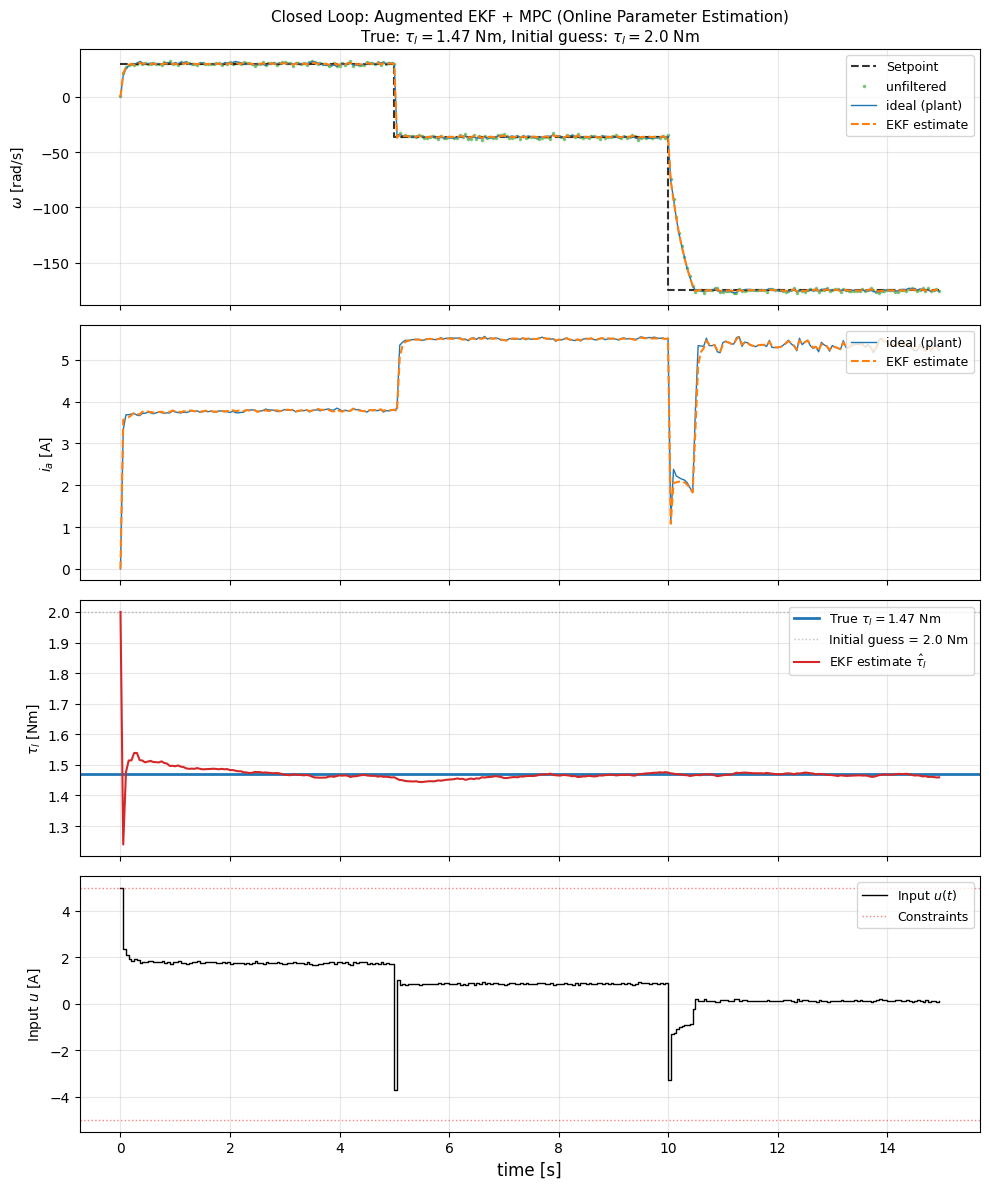

In [14]:
from casadi import *
from casadi.tools import *
import numpy as np
import matplotlib.pyplot as plt

# =========================
# 1. System Parameters
# =========================
# Common parameters
Ra = 12.345
La = 0.314
km = 0.253
J = 0.00441
B = 0.00732
ua = 60.0
dt = 0.05

# *** MODEL-PLANT MISMATCH ***
tl_plant = 1.47  # True plant torque (UNKNOWN to controller)
tl_model_init = 2.0   # Initial guess for model torque

# Noise Statistics (continuous-time interpretation)
var_v = 1.0      # Measurement noise
var_w1 = 0.01    # Process noise (current)
var_w2 = 100.0   # Process noise (omega)
var_w3 = 0.001   # Process noise (parameter τ_l - small for slow variation)

# Convert to discrete-time for EKF
Q_ekf = np.diag([var_w1 * dt**2, var_w2 * dt**2, var_w3 * dt**2])
R_ekf = np.array([[var_v]])

# Dimensions
nx_orig = 2  # Original states [ia, omega]
nx = 3       # Augmented states [ia, omega, τ_l]
nu = 1       # [u]
ny = 1       # [y = omega]

# MPC Settings
N = 30
K = 2
K1 = K + 1

# Constraints
u_min, u_max = -5.0, 5.0
ia_min, ia_max = -10.0, 10.0
w_min, w_max = -200.0, 35.0

# =========================
# 2. CasADi Functions
# =========================

# *** PLANT MODEL (uses true unknown torque tl_plant) ***
x_plant = SX.sym("x_plant", nx_orig)
u_plant = SX.sym("u_plant", nu)
ia_plant, om_plant = x_plant[0], x_plant[1]

xdot_plant = vertcat(
    -(Ra / La) * ia_plant - (km / La) * om_plant * u_plant[0] + (ua / La),
    -(B / J) * om_plant + (km / J) * ia_plant * u_plant[0] - (tl_plant / J)
)
f_cont_plant = Function('f_cont_plant', [x_plant, u_plant], [xdot_plant])

# Integrator for accurate plant simulation
ode_plant = {'x': x_plant, 'p': u_plant, 'ode': xdot_plant}
plant_integrator = integrator('F_plant', 'idas', ode_plant, {'tf': dt})


# *** AUGMENTED MODEL (states + parameter: [ia, omega, τ_l]) ***
x_aug = SX.sym("x_aug", nx)
u_model = SX.sym("u_model", nu)
ia_model, om_model, tl_est = x_aug[0], x_aug[1], x_aug[2]

# Dynamics with estimated parameter τ_l
xdot_aug = vertcat(
    -(Ra / La) * ia_model - (km / La) * om_model * u_model[0] + (ua / La),
    -(B / J) * om_model + (km / J) * ia_model * u_model[0] - (tl_est / J),
    0.0  # Parameter dynamics: dτ_l/dt = 0 (constant, but we add noise)
)
f_cont_aug = Function('f_cont_aug', [x_aug, u_model], [xdot_aug])

# Discretize AUGMENTED model (RK4) for EKF
k1 = f_cont_aug(x_aug, u_model)
k2 = f_cont_aug(x_aug + dt / 2 * k1, u_model)
k3 = f_cont_aug(x_aug + dt / 2 * k2, u_model)
k4 = f_cont_aug(x_aug + dt * k3, u_model)
x_next_aug = x_aug + (dt / 6) * (k1 + 2 * k2 + 2 * k3 + k4)
f_disc_aug = Function('f_disc_aug', [x_aug, u_model], [x_next_aug])

# =========================
# 3. AUGMENTED EKF Setup
# =========================
# Jacobian of the AUGMENTED model (discrete)
A_aug = jacobian(x_next_aug, x_aug)
C_aug = jacobian(x_aug[1], x_aug)  # Measurement: y = omega, C = [0, 1, 0]

A_aug_fun = Function('A_aug_fun', [x_aug, u_model], [A_aug])
C_aug_fun = Function('C_aug_fun', [x_aug], [C_aug])

# Initial covariance (larger uncertainty for parameter)
P_0 = np.diag([1.0, 100.0, 1.0])  # [ia, omega, τ_l]


def ekf_predict(x_hat, u_k, P):

    # a priori state estimate
    x_pred = f_disc_aug(x_hat, u_k).full()

    # a priori covariance
    A_k = A_aug_fun(x_hat, u_k).full()
    P_pred = A_k @ P @ A_k.T + Q_ekf
    return x_pred, P_pred


def ekf_update(x_pred, P_pred, y_meas):

    # Measurement Jacobian C = [0, 1, 0] (only omega is measured)
    C_k = C_aug_fun(x_pred).full()

    # Predicted measurement
    y_pred = x_pred[1]  # omega

    # Ensure proper shapes
    y_meas = y_meas.reshape(-1, 1)
    y_pred = y_pred.reshape(-1, 1)

    # Innovation
    innovation = y_meas - y_pred

    # Kalman Gain
    S = C_k @ P_pred @ C_k.T + R_ekf
    K_gain = P_pred @ C_k.T @ np.linalg.inv(S)

    # Corrected estimate (updates all 3 states including τ_l!)
    x_new = x_pred + K_gain @ innovation
    P_new = (np.eye(nx) - K_gain @ C_k) @ P_pred

    # Enforce symmetry
    P_new = (P_new + P_new.T) / 2
    
    return x_new, P_new


# =========================
# 4. MPC Setup (uses estimated parameter from EKF)
# =========================
# For MPC, we need to create a parameterized model that uses the estimated τ_l

# Collocation points (Radau)
tau_col = [0.0] + collocation_points(K, "radau")
tau = SX.sym("tau")


# Polynomial basis
def L(j):
    lj = 1
    for r in range(K1):
        if r != j: 
            lj *= (tau - tau_col[r]) / (tau_col[j] - tau_col[r])
    return lj


A_coll = np.zeros((K1, K1))
D_coll = np.zeros((K1, 1))
for j in range(K1):
    dLj = Function(f"dLj{j}", [tau], [jacobian(L(j), tau)])
    Lj = Function(f"Lj{j}", [tau], [L(j)])
    for k in range(K1): 
        A_coll[j, k] = float(dLj(tau_col[k]))
    D_coll[j] = float(Lj(1.0))

# NLP Structure (MPC uses only physical states [ia, omega])
opt = struct_symSX([
    entry("x", shape=(nx_orig,), repeat=[N + 1, K1]),  # Only ia, omega
    entry("u", shape=(nu,), repeat=[N])
])

# Decision variables & Parameters
w_opt = opt.cat
x_init = SX.sym("x_init", nx_orig)  # Initial [ia, omega] from EKF
tl_param = SX.sym("tl_param")  # Estimated τ_l from EKF (as parameter)
w_sp = SX.sym("w_sp")
p = vertcat(x_init, tl_param, w_sp)

# Cost weights
Qw, Qi, Ru = 5.0, 0.5, 20.0

Jcost = 0
g, lbg, ubg = [], [], []

# Initial Constraint
g.append(opt["x", 0, 0] - x_init)
lbg += [0.0] * nx_orig
ubg += [0.0] * nx_orig

# Parameterized dynamics for MPC (uses estimated tl_param)
x_mpc = SX.sym("x_mpc", nx_orig)
u_mpc = SX.sym("u_mpc", nu)
tl_mpc = SX.sym("tl_mpc")
ia_mpc, om_mpc = x_mpc[0], x_mpc[1]

xdot_mpc = vertcat(
    -(Ra / La) * ia_mpc - (km / La) * om_mpc * u_mpc[0] + (ua / La),
    -(B / J) * om_mpc + (km / J) * ia_mpc * u_mpc[0] - (tl_mpc / J)
)
f_cont_mpc = Function('f_cont_mpc', [x_mpc, u_mpc, tl_mpc], [xdot_mpc])

for i in range(N):
    # Cost
    st = opt["x", i, 0]
    ui = opt["u", i]
    Jcost += Qw * (st[1] - w_sp) ** 2 + Qi * (st[0]) ** 2 + Ru * (ui[0]) ** 2

    # Dynamics Constraints (Collocation) - uses estimated parameter
    for k in range(1, K1):
        x_ik = opt["x", i, k]
        fk = f_cont_mpc(x_ik, ui, tl_param)  # Uses estimated τ_l
        gk = 0
        for j in range(K1): 
            gk += A_coll[j, k] * opt["x", i, j]
        g.append(gk - dt * fk)
        lbg += [0.0] * nx_orig
        ubg += [0.0] * nx_orig

    # Continuity
    x_end = 0
    for j in range(K1): 
        x_end += D_coll[j] * opt["x", i, j]
    g.append(opt["x", i + 1, 0] - x_end)
    lbg += [0.0] * nx_orig
    ubg += [0.0] * nx_orig

# Terminal Cost
Jcost += Qw * (opt["x", N, 0][1] - w_sp) ** 2 + Qi * (opt["x", N, 0][0]) ** 2
g = vertcat(*g)

# Bounds
lbw = opt(0)
ubw = opt(0)
for i in range(N + 1):
    for j in range(K1):
        lbw["x", i, j] = [ia_min, w_min]
        ubw["x", i, j] = [ia_max, w_max]
for i in range(N):
    lbw["u", i] = [u_min]
    ubw["u", i] = [u_max]

# Solver
nlp = {"x": w_opt, "f": Jcost, "g": g, "p": p}
opts = {
    "ipopt.print_level": 0, 
    "print_time": 0, 
    "ipopt.tol": 1e-4, 
    "ipopt.warm_start_init_point": "yes"
}
solver = nlpsol("solver", "ipopt", nlp, opts)


# --- MPC Helpers ---
def make_guess(xk, prev_sol=None):
    """xk is [ia, omega] (2D)"""
    w0 = opt(0)
    if prev_sol is None:
        for i in range(N + 1):
            for j in range(K1): 
                w0["x", i, j] = xk
    else:
        last_x, last_u = prev_sol["x"], prev_sol["u"]
        for i in range(N): 
            w0["x", i] = last_x[i + 1]
        w0["x", N] = last_x[N]
        for i in range(N - 1): 
            w0["u", i] = last_u[i + 1]
        w0["u", N - 1] = last_u[N - 1]
    return w0


# =========================
# 5. Simulation Loop WITH PARAMETER ESTIMATION
# =========================
def run_simulation(setpoint_schedule, steps=300):

    print(f"Starting Simulation WITH AUGMENTED EKF (Parameter Estimation)")
    print(f"True plant torque: τ_l = {tl_plant} Nm (UNKNOWN)")
    print(f"Initial guess:     τ_l = {tl_model_init} Nm")
    print(f"EKF will estimate τ_l online...")
    np.random.seed(42)

    # Initial Conditions
    x_true = np.zeros((nx_orig, 1))  # True plant state [ia, omega]
    x_est = np.zeros((nx, 1))        # EKF estimate [ia, omega, τ_l]
    x_est[2, 0] = tl_model_init      # Initial guess for τ_l
    P_est = P_0.copy()

    # Warm start memory
    opt_sol = None

    # Histories
    hist_x_true = []
    hist_x_est = []
    hist_tl_est = []  # Parameter estimate history
    hist_y_meas = []
    hist_u = []
    hist_wsp = []

    # Setpoint scheduling
    sp_times = []
    sp_values = []
    cumulative_time = 0
    for sp_val, duration in setpoint_schedule:
        sp_times.append(cumulative_time)
        sp_values.append(sp_val)
        cumulative_time += duration

    # --- Main Loop ---
    for k in range(steps):
        # Determine current setpoint
        wsp = sp_values[0]
        for i in range(len(sp_times)):
            if k >= sp_times[i]:
                wsp = sp_values[i]

        # ===========================================
        # STEP 1: MEASUREMENT (from current x_true PLANT)
        # ===========================================
        v_noise = np.random.normal(0, np.sqrt(var_v))
        y_meas = x_true[1] + v_noise  # Only omega is measured
        y_meas = y_meas.reshape(-1, 1)

        # ===========================================
        # STEP 2: EKF UPDATE (Correction)
        # ===========================================
        if k == 0:
            # Initial estimate
            x_est[0:2] = x_true.copy()  # Perfect initial state
            x_est[2, 0] = tl_model_init  # Initial parameter guess
            P_est = P_0.copy()
        else:
            # Update using prediction from previous step
            x_est, P_est = ekf_update(x_pred_a_priori, P_pred_a_priori, y_meas)

        # ===========================================
        # STEP 3: MPC CONTROL (using EKF estimate)
        # ===========================================
        # Extract physical states and parameter
        x_est_phys = x_est[0:2]  # [ia, omega]
        tl_est_current = float(x_est[2, 0])  # Estimated τ_l
        
        w0 = make_guess(x_est_phys, opt_sol)
        pk = vertcat(x_est_phys, tl_est_current, wsp)

        sol = solver(x0=w0, lbx=lbw, ubx=ubw, lbg=lbg, ubg=ubg, p=pk)

        if solver.stats()['success']:
            opt_sol = opt(sol["x"])
            u_k = opt_sol["u", 0].full()
        else:
            print(f"Warning: MPC failed at step {k}")
            u_k = hist_u[-1] if hist_u else np.zeros((nu, 1))

        # ===========================================
        # STEP 4: LOG CURRENT STATE (BEFORE propagation)
        # ===========================================
        hist_x_true.append(x_true.flatten())
        hist_x_est.append(x_est[0:2].flatten())  # Only physical states
        hist_tl_est.append(tl_est_current)  # Parameter estimate
        hist_y_meas.append(y_meas.flatten())
        hist_u.append(u_k.flatten())
        hist_wsp.append(wsp)

        # ===========================================
        # STEP 5: PLANT PROPAGATION (with noise, uses PLANT)
        # ===========================================
        res = plant_integrator(x0=x_true, p=u_k)
        x_true_next = res["xf"].full()

        # Add process noise (continuous-time interpretation)
        w_noise = np.array([
            np.random.normal(0, np.sqrt(var_w1)),
            np.random.normal(0, np.sqrt(var_w2))
        ]).reshape(nx_orig, 1)

        # Inject as additive noise scaled by dt
        x_true = x_true_next + (w_noise * dt)

        # ===========================================
        # STEP 6: EKF PREDICTION for next step
        # ===========================================
        x_pred_a_priori, P_pred_a_priori = ekf_predict(x_est, u_k, P_est)

    return (
        np.array(hist_x_true), 
        np.array(hist_x_est), 
        np.array(hist_tl_est),
        np.array(hist_y_meas), 
        np.array(hist_u), 
        np.array(hist_wsp)
    )


# =========================
# Performance Metrics
# =========================
def compute_performance_metrics(Xt, U, W, dt):

    omega_true = Xt[:, 1]
    tracking_error = omega_true - W
    
    rmse = np.sqrt(np.mean(tracking_error**2))
    iae = np.sum(np.abs(tracking_error)) * dt
    ise = np.sum(tracking_error**2) * dt
    control_effort = np.sum(U**2) * dt
    max_error = np.max(np.abs(tracking_error))
    
    return {
        'RMSE': rmse,
        'IAE': iae,
        'ISE': ise,
        'Control_Effort': control_effort,
        'Max_Error': max_error
    }


# =========================
# 6. Execution & Plotting
# =========================
if __name__ == "__main__":
    # Define setpoints
    setpoint_schedule = [
        (30, 100),    # 30 rad/s for first 100 steps (0-5 seconds)
        (-36, 100),   # -36 rad/s for next 100 steps (5-10 seconds)
        (-175, 100)   # -175 rad/s for final 100 steps (10-15 seconds)
    ]

    # Run closed loop simulation
    Xt, Xe, Tl_est, Ym, U, W = run_simulation(setpoint_schedule, steps=300)
    
    # Compute performance metrics
    metrics = compute_performance_metrics(Xt, U, W, dt)
    print("\n" + "="*60)
    print("PERFORMANCE METRICS (AUGMENTED EKF + PARAMETER ESTIMATION)")
    print("="*60)
    print(f"True plant torque:      τ_l = {tl_plant} Nm")
    print(f"Initial guess:          τ_l = {tl_model_init} Nm")
    print(f"Final estimate:         τ_l = {Tl_est[-1]:.4f} Nm")
    print(f"Estimation error:       Δτ_l = {abs(Tl_est[-1] - tl_plant):.4f} Nm")
    print(f"Convergence:            {abs(Tl_est[-1] - tl_plant) / tl_plant * 100:.2f}% error")
    print("-"*60)
    print(f"RMSE (tracking):        {metrics['RMSE']:.4f} rad/s")
    print(f"IAE (tracking):         {metrics['IAE']:.4f} rad")
    print(f"ISE (tracking):         {metrics['ISE']:.4f} rad²")
    print(f"Control Effort:         {metrics['Control_Effort']:.4f} A²·s")
    print(f"Max Absolute Error:     {metrics['Max_Error']:.4f} rad/s")
    print("="*60 + "\n")

    # Time vector
    t = np.arange(len(U)) * dt

    # Create Figure with 4 subplots
    fig, ax = plt.subplots(4, 1, figsize=(10, 12), sharex=True)

    # -----------------------------
    # Plot 1: Angular Velocity (Omega)
    # -----------------------------
    ax[0].set_title(
        f"Closed Loop: Augmented EKF + MPC (Online Parameter Estimation)\n"
        f"True: $\\tau_l={tl_plant}$ Nm, Initial guess: $\\tau_l={tl_model_init}$ Nm",
        fontsize=11
    )

    # Setpoint
    ax[0].step(t, W, 'k--', linewidth=1.5, label='Setpoint', where='post', alpha=0.8)

    # Noisy Measurements
    ax[0].scatter(t, Ym, c='tab:green', s=10, alpha=0.5, label='unfiltered', marker='.')

    # True Plant
    ax[0].plot(t, Xt[:, 1], color='tab:blue', linewidth=1, label='ideal (plant)')

    # EKF Estimate
    ax[0].plot(t, Xe[:, 1], color='tab:orange', linestyle='--', linewidth=1.5, label='EKF estimate')

    ax[0].set_ylabel('$\omega$ [rad/s]', fontsize=10)
    ax[0].legend(loc='upper right', fontsize=9)
    ax[0].grid(True, alpha=0.3)

    # -----------------------------
    # Plot 2: Armature Current (ia)
    # -----------------------------
    # True Plant
    ax[1].plot(t, Xt[:, 0], color='tab:blue', linewidth=1, label='ideal (plant)')
    # EKF Estimate
    ax[1].plot(t, Xe[:, 0], color='tab:orange', linestyle='--', linewidth=1.5, label='EKF estimate')

    ax[1].set_ylabel('$i_a$ [A]', fontsize=10)
    ax[1].legend(loc='upper right', fontsize=9)
    ax[1].grid(True, alpha=0.3)

    # -----------------------------
    # Plot 3: PARAMETER ESTIMATE (τ_l) *** NEW ***
    # -----------------------------
    # True value (horizontal line)
    ax[2].axhline(tl_plant, color='tab:blue', linewidth=2, 
                  linestyle='-', label=f'True $\\tau_l = {tl_plant}$ Nm')
    
    # Initial guess (horizontal dashed line)
    ax[2].axhline(tl_model_init, color='gray', linewidth=1, 
                  linestyle=':', label=f'Initial guess = {tl_model_init} Nm', alpha=0.5)
    
    # Estimated parameter
    ax[2].plot(t, Tl_est, color='tab:red', linewidth=1.5, 
               label='EKF estimate $\\hat{\\tau}_l$')

    ax[2].set_ylabel('$\\tau_l$ [Nm]', fontsize=10)
    ax[2].legend(loc='upper right', fontsize=9)
    ax[2].grid(True, alpha=0.3)

    # -----------------------------
    # Plot 4: Input (Field Current)
    # -----------------------------
    ax[3].step(t, U, 'k-', where='post', linewidth=1, label='Input $u(t)$')
    ax[3].axhline(u_min, color='r', linestyle=':', linewidth=1, alpha=0.5, label='Constraints')
    ax[3].axhline(u_max, color='r', linestyle=':', linewidth=1, alpha=0.5)

    ax[3].set_ylabel('Input $u$ [A]', fontsize=10)
    ax[3].set_xlabel('time [s]', fontsize=12)
    ax[3].legend(loc='upper right', fontsize=9)
    ax[3].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('task3_AUGMENTED_EKF_parameter_estimation.png', dpi=150, bbox_inches='tight')
    plt.show()

<h3>Now let's check the tracking performance without EKF and no parameter Estimation </h3>

TASK 3: MPC WITHOUT EKF

MPC WITHOUT EKF
Plant torque: τ_l = 1.47 Nm (TRUE)
Model torque: τ_l = 2.0 Nm (WRONG - used by MPC)
Mismatch:     Δτ_l = 0.53 Nm (36.1%)

ia Estimation Method:
  - Initially: ia = 0
  - Then: Simple Euler propagation using measured omega

Simulation completed!
MPC Failures: 297/300 (99.0%)

PERFORMANCE METRICS
RMSE (tracking):        132.3948 rad/s
IAE (tracking):         1516.7954 rad
ISE (tracking):         262925.8892 rad²
Control Effort:         158.2693 A²·s
Max Absolute Error:     217.0411 rad/s



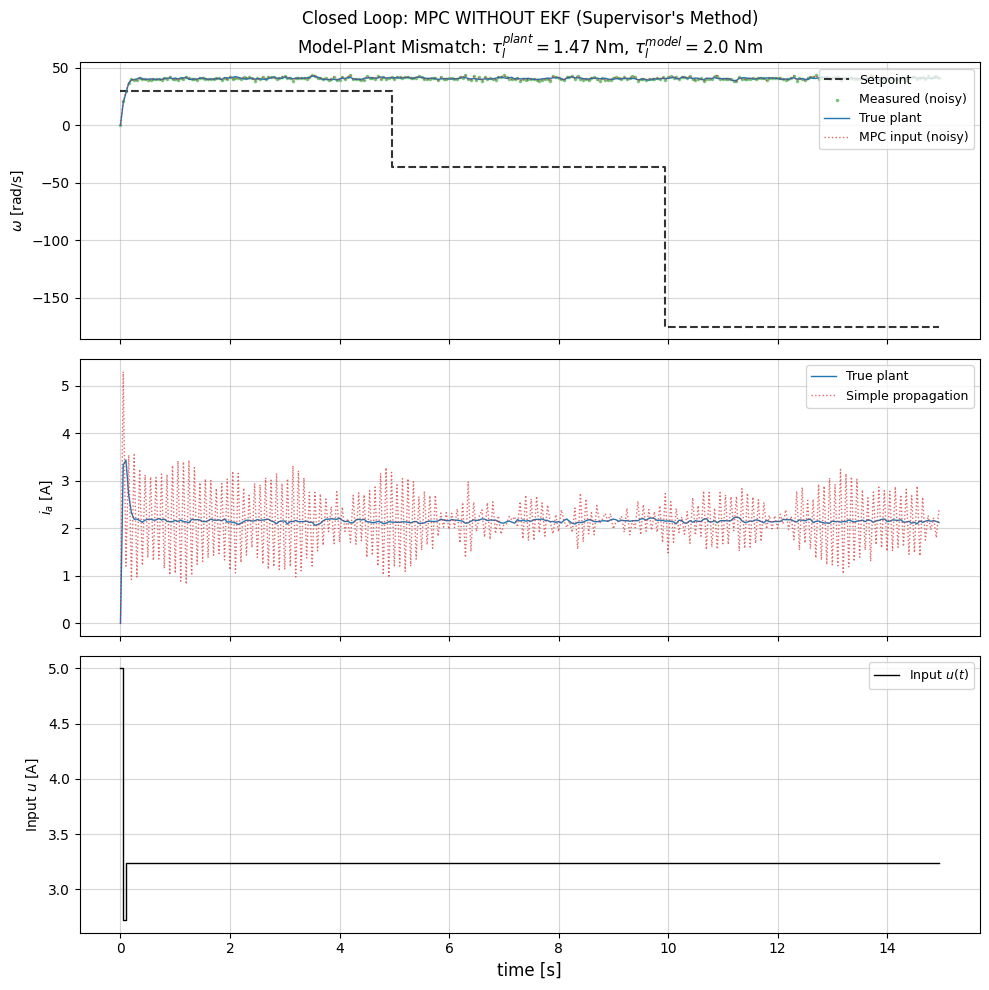

In [16]:
from casadi import *
from casadi.tools import *
import numpy as np
import matplotlib.pyplot as plt

# =========================
# 1. System Parameters
# =========================
# Common parameters
Ra = 12.345
La = 0.314
km = 0.253
J = 0.00441
B = 0.00732
ua = 60.0
dt = 0.05

# *** MODEL-PLANT MISMATCH ***
tl_plant = 1.47  # True plant torque (actual system)
tl_model = 2.0   # Model torque (used by MPC) - WRONG!

# Noise Statistics
var_v = 1.0      # Measurement noise
var_w1 = 0.01    # Process noise (current)
var_w2 = 100.0   # Process noise (omega)

# Dimensions
nx = 2  # [ia, omega]
nu = 1  # [u]
ny = 1  # [y]

# MPC Settings
N = 30
K = 2
K1 = K + 1

# Constraints
u_min, u_max = -5.0, 5.0
ia_min, ia_max = -10.0, 10.0
w_min, w_max = -200.0, 35.0

# =========================
# 2. CasADi Functions
# =========================

# *** PLANT MODEL (uses true torque tl_plant) ***
x_plant = SX.sym("x_plant", nx)
u_plant = SX.sym("u_plant", nu)
ia_plant, om_plant = x_plant[0], x_plant[1]

xdot_plant = vertcat(
    -(Ra / La) * ia_plant - (km / La) * om_plant * u_plant[0] + (ua / La),
    -(B / J) * om_plant + (km / J) * ia_plant * u_plant[0] - (tl_plant / J)
)

# Integrator for accurate plant simulation
ode_plant = {'x': x_plant, 'p': u_plant, 'ode': xdot_plant}
plant_integrator = integrator('F_plant', 'idas', ode_plant, {'tf': dt})


# *** MPC MODEL (uses WRONG torque tl_model) ***
x_model = SX.sym("x_model", nx)
u_model = SX.sym("u_model", nu)
ia_model, om_model = x_model[0], x_model[1]

xdot_model = vertcat(
    -(Ra / La) * ia_model - (km / La) * om_model * u_model[0] + (ua / La),
    -(B / J) * om_model + (km / J) * ia_model * u_model[0] - (tl_model / J)
)
f_cont_model = Function('f_cont_model', [x_model, u_model], [xdot_model])


# =========================
# 3. MPC Setup (Orthogonal Collocation)
# =========================
# Collocation points (Radau)
tau_col = [0.0] + collocation_points(K, "radau")
tau = SX.sym("tau")

# Polynomial basis
def L(j):
    lj = 1
    for r in range(K1):
        if r != j: lj *= (tau - tau_col[r]) / (tau_col[j] - tau_col[r])
    return lj

A_coll = np.zeros((K1, K1))
D_coll = np.zeros((K1, 1))
for j in range(K1):
    dLj = Function(f"dLj{j}", [tau], [jacobian(L(j), tau)])
    Lj = Function(f"Lj{j}", [tau], [L(j)])
    for k in range(K1): A_coll[j, k] = float(dLj(tau_col[k]))
    D_coll[j] = float(Lj(1.0))

# NLP Structure
opt = struct_symSX([
    entry("x", shape=(nx,), repeat=[N + 1, K1]),
    entry("u", shape=(nu,), repeat=[N])
])

# Decision variables & Parameters
w_opt = opt.cat
x_init = SX.sym("x_init", nx)
w_sp = SX.sym("w_sp")
p = vertcat(x_init, w_sp)

# Costs
Qw, Qi, Ru = 5.0, 0.5, 20.0

Jcost = 0
g, lbg, ubg = [], [], []

# Initial Constraint
g.append(opt["x", 0, 0] - x_init)
lbg += [0.0] * nx
ubg += [0.0] * nx

for i in range(N):
    # Cost
    st = opt["x", i, 0]
    ui = opt["u", i]
    Jcost += Qw * (st[1] - w_sp) ** 2 + Qi * (st[0]) ** 2 + Ru * (ui[0]) ** 2

    # Dynamics Constraints (Collocation) - uses WRONG MODEL
    for k in range(1, K1):
        x_ik = opt["x", i, k]
        fk = f_cont_model(x_ik, ui)
        gk = 0
        for j in range(K1): gk += A_coll[j, k] * opt["x", i, j]
        g.append(gk - dt * fk)
        lbg += [0.0] * nx
        ubg += [0.0] * nx

    # Continuity
    x_end = 0
    for j in range(K1): x_end += D_coll[j] * opt["x", i, j]
    g.append(opt["x", i + 1, 0] - x_end)
    lbg += [0.0] * nx
    ubg += [0.0] * nx

# Terminal Cost
Jcost += Qw * (opt["x", N, 0][1] - w_sp) ** 2 + Qi * (opt["x", N, 0][0]) ** 2
g = vertcat(*g)

# Bounds
lbw = opt(0)
ubw = opt(0)
for i in range(N + 1):
    for j in range(K1):
        lbw["x", i, j] = [ia_min, w_min]
        ubw["x", i, j] = [ia_max, w_max]
for i in range(N):
    lbw["u", i] = [u_min]
    ubw["u", i] = [u_max]

# Solver
nlp = {"x": w_opt, "f": Jcost, "g": g, "p": p}
opts = {
    "ipopt.print_level": 0, 
    "print_time": 0, 
    "ipopt.tol": 1e-4,
    "ipopt.max_iter": 500,
    "ipopt.warm_start_init_point": "yes",
    "ipopt.mu_strategy": "adaptive",
    "ipopt.acceptable_tol": 1e-3,
    "ipopt.acceptable_iter": 5
}
solver = nlpsol("solver", "ipopt", nlp, opts)


# --- MPC Helpers ---
def make_guess(xk, prev_sol=None):
    w0 = opt(0)
    if prev_sol is None:
        for i in range(N + 1):
            for j in range(K1): w0["x", i, j] = xk
    else:
        last_x, last_u = prev_sol["x"], prev_sol["u"]
        for i in range(N): w0["x", i] = last_x[i + 1]
        w0["x", N] = last_x[N]
        for i in range(N - 1): w0["u", i] = last_u[i + 1]
        w0["u", N - 1] = last_u[N - 1]
    return w0


# =========================
# 4. Simple ia Propagation Function
# =========================
def propagate_ia_simple(ia_prev, omega_measured, u_prev, dt):

    # Model dynamics for ia (first equation)
    dia_dt = -(Ra/La)*ia_prev - (km/La)*omega_measured*u_prev + (ua/La)
    
    # Forward Euler step
    ia_estimate = ia_prev + dt * dia_dt
    
    return ia_estimate


# =========================
# 5. Simulation WITHOUT EKF (Supervisor's Method)
# =========================
def run_simulation_without_ekf(setpoint_schedule, steps=300):

    print(f"\n{'='*70}")
    print(f"MPC WITHOUT EKF")
    print(f"{'='*70}")
    print(f"Plant torque: τ_l = {tl_plant} Nm (TRUE)")
    print(f"Model torque: τ_l = {tl_model} Nm (WRONG - used by MPC)")
    print(f"Mismatch:     Δτ_l = {abs(tl_plant - tl_model):.2f} Nm ({abs(tl_plant-tl_model)/tl_plant*100:.1f}%)")
    print(f"\nia Estimation Method:")
    print(f"  - Initially: ia = 0")
    print(f"  - Then: Simple Euler propagation using measured omega")
    print(f"{'='*70}\n")
    
    np.random.seed(42)

    # Initial Conditions
    x_true = np.zeros((nx, 1))  # True plant state
    ia_estimate = 0.0  # Initial ia estimate
    u_prev = 0.0  # Previous control
    opt_sol = None

    # Histories
    hist_x_true = []
    hist_x_mpc = []
    hist_y_meas = []
    hist_u = []
    hist_wsp = []
    
    failure_count = 0

    # Setpoint scheduling
    sp_times = []
    sp_values = []
    cumulative_time = 0
    for sp_val, duration in setpoint_schedule:
        sp_times.append(cumulative_time)
        sp_values.append(sp_val)
        cumulative_time += duration

    # --- Main Loop ---
    for k in range(steps):

        # Determine current setpoint
        wsp = sp_values[0]
        for i in range(len(sp_times)):
            if k >= sp_times[i]:
                wsp = sp_values[i]

        # ===========================================
        # STEP 1: MEASUREMENT (from true plant)
        # ===========================================
        v_noise = np.random.normal(0, np.sqrt(var_v))
        y_meas = float(x_true[1, 0] + v_noise)
        
        # ===========================================
        # STEP 2: Estimate ia using simple propagation
        # ===========================================
        if k == 0:
            # Initial guess
            ia_estimate = 0.0
        else:
            # Propagate ia using measured omega and previous values
            ia_estimate = propagate_ia_simple(ia_estimate, y_meas, u_prev, dt)
        
        # Construct state for MPC
        x_mpc = np.array([ia_estimate, y_meas]).reshape(-1, 1)
        
        # ===========================================
        # STEP 3: MPC CONTROL (using WRONG MODEL)
        # ===========================================
        w0 = make_guess(x_mpc, opt_sol)
        pk = vertcat(x_mpc, wsp)

        sol = solver(x0=w0, lbx=lbw, ubx=ubw, lbg=lbg, ubg=ubg, p=pk)

        if solver.stats()['success']:
            opt_sol = opt(sol["x"])
            u_k = float(opt_sol["u", 0])
        else:
            failure_count += 1
            if k > 0:
                u_k = u_prev
            else:
                u_k = 0.0

        # ===========================================
        # STEP 4: LOGGING
        # ===========================================
        hist_x_true.append(x_true.flatten())
        hist_x_mpc.append(x_mpc.flatten())
        hist_y_meas.append(y_meas)
        hist_u.append(u_k)
        hist_wsp.append(wsp)

        # ===========================================
        # STEP 5: PLANT PROPAGATION (with noise, uses TRUE model)
        # ===========================================
        res = plant_integrator(x0=x_true, p=u_k)
        x_true_next = res["xf"].full()

        # Add Process Noise
        w_noise = np.array([
            np.random.normal(0, np.sqrt(var_w1)),
            np.random.normal(0, np.sqrt(var_w2))
        ]).reshape(nx, 1)

        x_true = x_true_next + (w_noise * dt)
        
        # Update previous control for next iteration
        u_prev = u_k

    print(f"Simulation completed!")
    print(f"MPC Failures: {failure_count}/{steps} ({failure_count/steps*100:.1f}%)\n")
    
    return (np.array(hist_x_true), np.array(hist_x_mpc), 
            np.array(hist_y_meas), np.array(hist_u), np.array(hist_wsp))


# =========================
# Performance Metrics
# =========================
def compute_performance_metrics(Xt, U, W, dt):

    omega_true = Xt[:, 1]
    tracking_error = omega_true - W
    
    rmse = np.sqrt(np.mean(tracking_error**2))
    iae = np.sum(np.abs(tracking_error)) * dt
    ise = np.sum(tracking_error**2) * dt
    control_effort = np.sum(U**2) * dt
    max_error = np.max(np.abs(tracking_error))
    
    return {
        'RMSE': rmse,
        'IAE': iae,
        'ISE': ise,
        'Control_Effort': control_effort,
        'Max_Error': max_error
    }


# =========================
# 6. Execution & Plotting
# =========================
if __name__ == "__main__":
    setpoint_schedule = [
        (30, 100),
        (-36, 100),
        (-175, 100)
    ]

    print("="*70)
    print("TASK 3: MPC WITHOUT EKF")
    print("="*70)
    
    Xt, Xmpc, Ym, U, W = run_simulation_without_ekf(setpoint_schedule, steps=300)
    
    # Compute performance metrics
    metrics = compute_performance_metrics(Xt, U, W, dt)
    print("="*70)
    print("PERFORMANCE METRICS")
    print("="*70)
    print(f"RMSE (tracking):        {metrics['RMSE']:.4f} rad/s")
    print(f"IAE (tracking):         {metrics['IAE']:.4f} rad")
    print(f"ISE (tracking):         {metrics['ISE']:.4f} rad²")
    print(f"Control Effort:         {metrics['Control_Effort']:.4f} A²·s")
    print(f"Max Absolute Error:     {metrics['Max_Error']:.4f} rad/s")
    print("="*70 + "\n")

    # Time vector
    t = np.arange(len(U)) * dt

    # Create Figure
    fig, ax = plt.subplots(3, 1, figsize=(10, 10), sharex=True)

    # Plot 1: Angular Velocity
    ax[0].set_title(
        f"Closed Loop: MPC WITHOUT EKF (Supervisor's Method)\n"
        f"Model-Plant Mismatch: $\\tau_l^{{plant}}={tl_plant}$ Nm, $\\tau_l^{{model}}={tl_model}$ Nm"
    )
    ax[0].step(t, W, 'k--', linewidth=1.5, label='Setpoint', alpha=0.8)
    ax[0].scatter(t, Ym, c='tab:green', s=10, alpha=0.5, label='Measured (noisy)', marker='.')
    ax[0].plot(t, Xt[:, 1], color='tab:blue', linewidth=1, label='True plant')
    ax[0].plot(t, Xmpc[:, 1], color='tab:red', linestyle=':', linewidth=1.0, label='MPC input (noisy)', alpha=0.7)
    ax[0].set_ylabel(r'$\omega$ [rad/s]', fontsize=10)
    ax[0].legend(loc='upper right', fontsize=9)
    ax[0].grid(True, alpha=0.5)

    # Plot 2: Armature Current
    ax[1].plot(t, Xt[:, 0], color='tab:blue', linewidth=1, label='True plant')
    ax[1].plot(t, Xmpc[:, 0], color='tab:red', linestyle=':', linewidth=1.0, label='Simple propagation', alpha=0.7)
    ax[1].set_ylabel(r'$i_a$ [A]', fontsize=10)
    ax[1].legend(loc='upper right', fontsize=9)
    ax[1].grid(True, alpha=0.5)

    # Plot 3: Input
    ax[2].step(t, U, 'k-', where='post', linewidth=1, label='Input $u(t)$')
    ax[2].set_ylabel('Input $u$ [A]', fontsize=10)
    ax[2].set_xlabel('time [s]', fontsize=12)
    ax[2].legend(loc='upper right', fontsize=9)
    ax[2].grid(True, alpha=0.5)

    plt.tight_layout()
    plt.show()

<div>
  <h3>Summary of Observations</h3>

  <h4>1. Augmented EKF Performance (Success)</h4>
  <ul>
    <li>
      <strong>Parameter Convergence:</strong> The EKF successfully estimates the unknown load torque online. It rapidly corrects the initial wrong guess (2.0 Nm) to the true value (1.47 Nm) within the first second.
    </li>
    <li>
      <strong>Perfect Tracking:</strong> Because the model parameter is corrected in real-time, the MPC achieves <strong>excellent tracking</strong> of the angular velocity (&omega;) with zero steady-state error.
    </li>
  </ul>

  <h4>2. MPC Without EKF (Failure)</h4>
  <ul>
    <li>
      <strong>Steady-State Offset:</strong> The controller operates with a fixed, incorrect model (&tau;<sub>l</sub> = 2.0 Nm) that assumes the load is heavier than it actually is. This causes a massive <strong>permanent offset</strong>, where the motor spins significantly faster than the setpoint because the controller applies excessive torque.
    </li>
    <li>
      <strong>Conclusion:</strong> The comparison proves that <strong>online parameter estimation is essential</strong> for this system to handle model-plant mismatch. Without it, the controller cannot eliminate the steady-state error.
    </li>
  </ul>
</div>